# Notebook 1: Bisakah graph database dikombinasikan dengan relational database biasa?

**Pilih kernel `Python (hybrid-db)`, lalu Run All.** Sekitar 3-4 menit, tanpa klik apa pun: notebook ini **menyalakan Neo4j**, menjalankan semua tes dan
pengukuran, lalu **mematikan** Neo4j lagi (hanya kalau notebook ini yang menyalakannya).

Eksperimennya: **SQLite** menyimpan profil, **Neo4j** menyimpan relasi pertemanan (data asli Pokec), **Python** menggabungkan keduanya. Pertanyaan dosen
dijawab dengan tes yang bisa lulus atau gagal, dan perbandingan yang diukur. **Jawaban akhir ada di Langkah 11**; penjelasan lengkap ada di laporan.

| Pertanyaan penelitian | Diuji di | Acuan dari pustaka (semua open access; tautan di bagian bawah) |
|---|---|---|
| **RQ1** Kedua basis data bisa diisi dari satu sumber dan tetap konsisten? | Langkah 3-4 | Fowler (2011), Lu dan Holubova (2019) |
| **RQ2** Query gabungan memberi jawaban yang benar? | Langkah 5 | Backstrom dan Leskovec (2011): struktur graf + atribut |
| **RQ3** Pertanyaan yang sama dijawab identik oleh keduanya? | Langkah 6 | Cheng dkk. (2019), Holsch dkk. (2017), Francis dkk. (2018) |
| **RQ4** Seberapa cepat, dan kapan masing-masing unggul? | Langkah 6, 8 | Rodriguez dan Neubauer (2010), Hassan dkk. (2018), Erling dkk. (2015), Georges dkk. (2007) |
| **RQ5** Apa biayanya (data ganda, lintas batas, sinkronisasi)? | Langkah 4, 7 | Fowler (2011), Yuan dkk. (2023) |

Tes yang error dicatat **GAGAL** dan tidak menghentikan notebook, jadi Run All selalu sampai ke langkah mematikan Neo4j.
Mau melihat grafnya di browser? Pakai `2_lihat_graf_di_browser.ipynb`.

In [1]:
import importlib.util
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Notebook boleh dibuka dari root proyek maupun dari folder notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scripts"))

import eksperimen as ek             # pengukuran, generator SQL, uji konsistensi (khusus notebook)
import neo4j_lokal                  # nyalakan / cek / matikan Neo4j (khusus notebook)
import uji_hybrid                   # jawaban kunci dari CSV + pencatat tes
import visualisasi as viz           # gambar

# 04_hybrid_queries.py diawali angka, jadi tidak bisa di-import dengan `import` biasa.
spec = importlib.util.spec_from_file_location("hybrid_queries", ROOT / "scripts" / "04_hybrid_queries.py")
hq = importlib.util.module_from_spec(spec)
spec.loader.exec_module(hq)

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)
tes = uji_hybrid.CatatanTes()      # mencatat LULUS / GAGAL + waktu tiap tes
kecepatan = {}                     # angka ringkas untuk Langkah 11
hasil = {}                         # semua hasil pengukuran; disimpan ke docs/hasil/ di akhir
MULAI_NOTEBOOK = time.perf_counter()
print("Siap.")

Siap.


## Langkah 1 - Cek kesiapan dan nyalakan Neo4j

Memeriksa kernel, password di `.env`, alamat Neo4j (harus localhost), file data, lalu **menyalakan Neo4j** di latar belakang tanpa jendela.
Butuh `NEO4J_HOME` di `.env` dan Java 17. Kalau Neo4j sudah menyala sebelum notebook dimulai, notebook ini tidak akan mematikannya.

In [2]:
tes.kelompok = "0. Persiapan"
status = neo4j_lokal.cek_kesiapan()
tes.catat("Prasyarat (password, localhost, CSV, SQLite) siap", status["wajib_ok"], "lihat daftar di atas")

sudah_menyala = neo4j_lokal.bolt_terbuka()
siap, ms = uji_hybrid.ukur(neo4j_lokal.nyalakan)
tes.catat("Neo4j menyala dan menerima koneksi", siap,
          "sudah menyala sebelum notebook dimulai" if sudah_menyala else "dinyalakan oleh notebook ini",
          None if sudah_menyala else ms)
if not sudah_menyala and siap:
    kecepatan["Neo4j menyala dari mati (detik)"] = round(ms / 1000, 1)

[OK]    Interpreter / kernel                 D:\Softwares\Anaconda\Miniconda\envs\hybrid-db\python.exe
[OK]    Password Neo4j di .env               terisi
[OK]    NEO4J_URI mengarah ke localhost      host = localhost
[OK]    CSV sampel (script 01)               ada
[OK]    Database SQLite (script 02)          ada
[OK]    NEO4J_HOME (untuk tombol nyalakan)   D:\Softwares\neo4j-community-5.26.31
[BELUM] Neo4j sedang menyala                 belum menyala (akan dinyalakan di langkah berikutnya)

>>> Lanjut: Neo4j belum menyala; dinyalakan di langkah berikutnya.
[LULUS] Prasyarat (password, localhost, CSV, SQLite) siap                    lihat daftar di atas


Menyalakan Neo4j dari D:\Softwares\neo4j-community-5.26.31 ... (hanya bisa diakses dari komputer ini)


[OK] Neo4j siap dalam 11 detik (port 7687). Browser interaktif: http://localhost:7474
[LULUS] Neo4j menyala dan menerima koneksi                       12634.5 ms  dinyalakan oleh notebook ini


## Langkah 2 - Graf terisi, koneksi dibuka, pemanasan

Graf diisi dari CSV oleh `scripts/03_sync_to_neo4j.py` **hanya kalau masih kosong**. Lalu koneksi ke Neo4j dan SQLite dibuka sekali untuk seluruh notebook, dan
dibuat tabel `friendships` di SQLite (salinan edge, khusus untuk membandingkan SQL dengan Cypher pada pertanyaan yang sama).

Jawaban kunci dihitung terpisah dari CSV dengan **Python murni**. Lima user uji dipilih bertingkat menurut jumlah teman (hub, persentil 1, 10, 25, 50), karena
graf sosial itu timpang (Barabasi dan Albert, 1999) dan satu user saja tidak mewakili.

In [3]:
tes.kelompok = "0. Persiapan"
n = neo4j_lokal.jumlah_user()
if n == 0:
    print("Graf masih kosong. Menjalankan scripts/03_sync_to_neo4j.py ...")
    kode, ms = uji_hybrid.ukur(lambda: neo4j_lokal.jalankan_script("03_sync_to_neo4j.py"))
    tes.catat("Isi graf dari CSV (script 03)", kode == 0, f"kode keluar {kode}", ms)
    kecepatan["Isi graf dari CSV, script 03 (detik)"] = round(ms / 1000, 1)
elif n and n > 0:
    print(f"Graf sudah terisi ({n:,} node User); pengisian dilewati.")
else:
    tes.catat("Isi graf dari CSV (script 03)", False, "Neo4j tidak bisa dihubungi atau login ditolak")

ref = uji_hybrid.Referensi()      # jawaban kunci: dihitung dari CSV dengan Python murni
derajat_py = pd.DataFrame({"user_id": [int(u) for u in ref.users["user_id"]],
                           "out_degree": [len(ref.keluar[int(u)]) for u in ref.users["user_id"]]})
users = ek.pilih_user_uji(derajat_py, 5)
print("User uji (user_id, jumlah teman keluar):", users)

driver = conn = sesi = None


def buka_koneksi():
    global driver, conn, sesi
    driver, conn = hq.connect_neo4j(), hq.connect_sqlite()
    sesi = ek.SesiCypher(driver)
    return ek.bangun_friendships(conn)      # salinan edge di SQLite: WITHOUT ROWID, PRIMARY KEY (user_id_1, user_id_2)


tes.jalankan("Koneksi Neo4j + SQLite terbuka; tabel friendships dibuat", buka_koneksi, None,
             lambda h, _: (h == ref.jumlah["FRIEND"], f"{h:,} baris edge di SQLite"))

Graf sudah terisi (4,505 node User); pengisian dilewati.
User uji (user_id, jumlah teman keluar): [(103095, 185), (111493, 87), (898460, 45), (37947, 26), (257768, 13)]


[LULUS] Koneksi Neo4j + SQLite terbuka; tabel friendships dibuat     137.5 ms  72,004 baris edge di SQLite


72004

  neo4j_server        Neo4j Kernel 5.26.31 community
  driver_neo4j_python 6.3.1
  sqlite              3.53.4
  python              3.13.16
  pandas              3.0.6
  os                  Windows-11-10.0.26200-SP0
  prosesor            Intel64 Family 6 Model 151 Stepping 2, GenuineIntel
  jumlah_cpu          20


Query yang sama: panggilan ke-1 512 ms, ke-2 88 ms, ke-3 64 ms, stabil sekitar 17 ms.


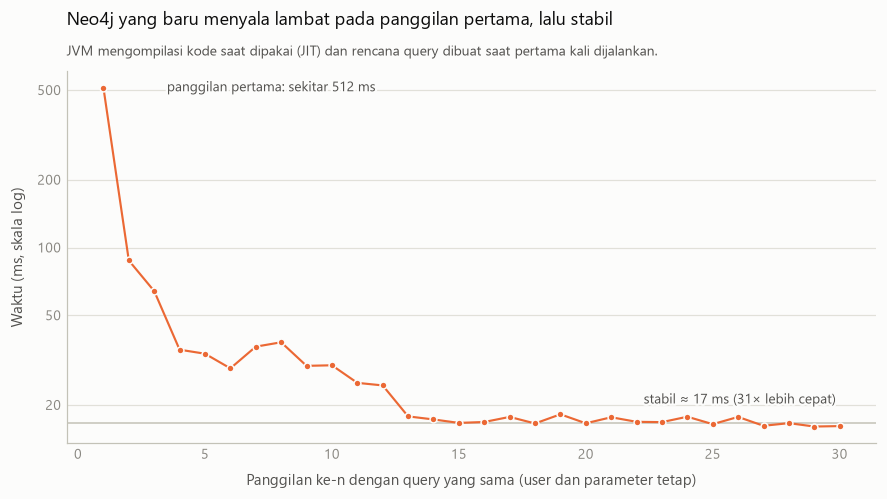

In [4]:
import os
import platform
import sqlite3

import neo4j

with tes.aman("Catat lingkungan pengukuran"):
    komponen = sesi.jalankan("CALL dbms.components() YIELD name, versions, edition RETURN name, versions[0] AS versi, edition")[0]
    hasil["lingkungan"] = {"neo4j_server": f"{komponen['name']} {komponen['versi']} {komponen['edition']}",
                           "driver_neo4j_python": neo4j.__version__, "sqlite": sqlite3.sqlite_version,
                           "python": platform.python_version(), "pandas": pd.__version__, "os": platform.platform(),
                           "prosesor": platform.processor(), "jumlah_cpu": os.cpu_count()}
    for kunci, nilai in hasil["lingkungan"].items():
        print(f"  {kunci:<20}{nilai}")

# Kurva pemanasan: hanya bermakna kalau Neo4j BARU dinyalakan oleh notebook ini (JVM masih dingin).
if sesi is not None and not sudah_menyala:
    with tes.aman("Kurva pemanasan Neo4j"):
        k = ek.kurva_pemanasan(sesi, users[3][0], 30)
        hasil["kurva_pemanasan"] = k
        stabil = statistics.median(k[-10:])
        kecepatan["Neo4j, query yang sama: panggilan ke-1 vs stabil (ms)"] = f"{k[0]:.0f} vs {stabil:.0f}"
        print(f"Query yang sama: panggilan ke-1 {k[0]:.0f} ms, ke-2 {k[1]:.0f} ms, ke-3 {k[2]:.0f} ms, stabil sekitar {stabil:.0f} ms.")
        viz.simpan(viz.gambar_pemanasan(k), "11_pemanasan_jvm")
        plt.show()
else:
    print("Neo4j sudah menyala sebelum notebook dimulai (sudah hangat), jadi kurva pemanasan dilewati.")

### Karakter sampel dibanding seluruh Pokec

Sampel (satu wilayah) harus mirip jaringan sosial sungguhan supaya hasil kinerjanya berarti. Ukuran struktur sampel dihitung dari CSV dan dibandingkan dengan statistik
seluruh Pokec yang dipublikasikan SNAP (graf lengkap 1,6 juta user). Perbedaan yang wajar: sampel hanya memuat relasi **di dalam** satu wilayah, jadi user tanpa teman
di wilayah itu terlihat terisolasi dan rata-rata relasi lebih kecil.

In [5]:
tes.kelompok = "0. Persiapan"
SNAP_POKEC = {"user": 1632803, "edge": 30622564, "klasterisasi_rata2": 0.1094, "komponen_terbesar": 1.0, "diameter_perkiraan": 11,
              "diameter_efektif_90": 5.2}     # https://snap.stanford.edu/data/soc-Pokec.html
pasangan_sampel = [(a, b) for a, tujuan in ref.keluar.items() for b in tujuan]
profil = tes.jalankan("Profil struktur sampel dihitung dari CSV", lambda: ek.profil_graf([int(u) for u in ref.users["user_id"]], pasangan_sampel),
                      None, lambda h, _: (h["user"] == ref.jumlah["User"] and h["edge"] == ref.jumlah["FRIEND"],
                                          f"resiprositas {h['resiprositas']:.1%}, klasterisasi {h['klasterisasi_rata2']:.3f}"))
if profil:
    hasil["profil_graf"] = profil
    tampil = [("Pengguna", f"{profil['user']:,}", f"{SNAP_POKEC['user']:,}"),
              ("Relasi berarah", f"{profil['edge']:,}", f"{SNAP_POKEC['edge']:,}"),
              ("Rata-rata relasi keluar per user", f"{profil['edge'] / profil['user']:.1f}", f"{SNAP_POKEC['edge'] / SNAP_POKEC['user']:.1f}"),
              ("Median / maksimum relasi keluar", f"{profil['median_out_degree']:.0f} / {profil['maks_out_degree']}", "-"),
              ("Relasi yang berbalas (resiprositas)", f"{profil['resiprositas']:.1%}", "-"),
              ("User tanpa relasi sama sekali", f"{profil['terisolasi']:.1%}", "0% (semua user ada di satu komponen)"),
              ("Komponen terhubung terbesar (tak berarah)", f"{profil['komponen_terbesar']:.1%}", f"{SNAP_POKEC['komponen_terbesar']:.0%}"),
              ("Koefisien klasterisasi rata-rata", f"{profil['klasterisasi_rata2']:.4f}", f"{SNAP_POKEC['klasterisasi_rata2']:.4f}"),
              ("Diameter (perkiraan batas bawah)", f"{profil['diameter_perkiraan']}", f"{SNAP_POKEC['diameter_perkiraan']}"),
              ("Diameter efektif (persentil ke-90)", f"{profil['diameter_efektif_90']:.1f}", f"{SNAP_POKEC['diameter_efektif_90']}")]
    display(pd.DataFrame(tampil, columns=["ukuran", "sampel (4.505 user)", "seluruh Pokec (SNAP)"]))

[LULUS] Profil struktur sampel dihitung dari CSV                  1355.3 ms  resiprositas 71.1%, klasterisasi 0.188


,ukuran,sampel (4.505 user),seluruh Pokec (SNAP)
0,Pengguna,"4,505","1,632,803"
1,Relasi berarah,"72,004","30,622,564"
2,Rata-rata relasi keluar per user,16.0,18.8
3,Median / maksimum relasi keluar,10 / 185,-
4,Relasi yang berbalas (resiprositas),71.1%,-
5,User tanpa relasi sama sekali,11.1%,0% (semua user ada di satu komponen)
6,Komponen terhubung terbesar (tak berarah),88.3%,100%
7,Koefisien klasterisasi rata-rata,0.1884,0.1094
8,Diameter (perkiraan batas bawah),8,11
9,Diameter efektif (persentil ke-90),4.0,5.2


## Langkah 3 - RQ1: apakah kedua basis data konsisten?

Neo4j dan SQLite diisi dari CSV yang sama. Yang diuji: jumlah baris, integritas, dan **himpunan** isi kedua sisi (bukan sekadar jumlah): user, edge, pasangan user-hobi,
serta tiga atribut (`gender`, `age`, `region`) yang **sengaja diduplikasi** di node Neo4j supaya query graf bisa memfilter tanpa bolak-balik ke SQLite.

In [6]:
tes.kelompok = "1. Konsistensi lintas basis data"


def hitung_graf():
    with hq._koneksi() as (d, c):
        return {r["nama"]: r["jumlah"] for r in hq._cypher(d, "model_graf_jumlah.cypher")}


tes.jalankan("Graf Neo4j sama dengan CSV (node dan relasi)", hitung_graf, lambda: ref.jumlah,
             lambda h, k: (h == k, ", ".join(f"{a}={b:,}" for a, b in h.items())))


def cek_sqlite():
    return {
        "users": conn.execute("SELECT COUNT(*) FROM users").fetchone()[0],
        "hobbies": conn.execute("SELECT COUNT(*) FROM hobbies").fetchone()[0],
        "integrity": conn.execute("PRAGMA integrity_check").fetchone()[0],
        "fk_pelanggaran": len(conn.execute("PRAGMA foreign_key_check").fetchall()),
    }


tes.jalankan("SQLite: jumlah baris, integritas, foreign key", cek_sqlite,
             lambda: {"users": ref.jumlah["User"], "hobbies": ref.jumlah["HAS_HOBBY"], "integrity": "ok", "fk_pelanggaran": 0},
             lambda h, k: (h == k, f"users={h['users']:,}, hobbies={h['hobbies']:,}, integrity={h['integrity']}, "
                                   f"pelanggaran FK={h['fk_pelanggaran']}"))


def cocok_himpunan(h, _):
    ok = all(v == 0 for nama, v in h.items() if "hanya" in nama)
    return ok, (f"{h['jumlah_user']:,} user, {h['jumlah_edge']:,} edge, {h['jumlah_user_hobi']:,} pasangan user-hobi; "
                f"selisih di kedua arah: {sum(v for nama, v in h.items() if 'hanya' in nama)}")


tes.jalankan("Himpunan user, edge, dan user-hobi identik di Neo4j dan SQLite", lambda: ek.selisih_himpunan(sesi, conn), None, cocok_himpunan)
tes.jalankan("Atribut duplikat (gender, age, region) sinkron untuk semua user", lambda: ek.selisih_atribut(sesi, conn), None,
             lambda h, _: (h == [], f"{ref.jumlah['User'] * 3:,} nilai dibandingkan, {len(h)} berbeda"))


def pencarian_sqlite():
    ids = ref.users["user_id"].sample(1000, replace=True, random_state=1).tolist()
    rencana = " ".join(r[3] for r in conn.execute("EXPLAIN QUERY PLAN SELECT * FROM users WHERE user_id = ?", (ids[0],)))
    return rencana


tes.jalankan("SQLite: pencarian user_id memakai index (PRIMARY KEY)", pencarian_sqlite, None,
             lambda h, _: ("PRIMARY KEY" in h, h))

[LULUS] Graf Neo4j sama dengan CSV (node dan relasi)               309.1 ms  User=4,505, Hobby=60, FRIEND=72,004, HAS_HOBBY=19,512
[LULUS] SQLite: jumlah baris, integritas, foreign key               27.2 ms  users=4,505, hobbies=19,512, integrity=ok, pelanggaran FK=0


[LULUS] Himpunan user, edge, dan user-hobi identik di Neo4j dan SQLite    2579.3 ms  4,505 user, 72,004 edge, 19,512 pasangan user-hobi; selisih di kedua arah: 0
[LULUS] Atribut duplikat (gender, age, region) sinkron untuk semua user     164.0 ms  13,515 nilai dibandingkan, 0 berbeda
[LULUS] SQLite: pencarian user_id memakai index (PRIMARY KEY)        0.7 ms  SEARCH users USING INTEGER PRIMARY KEY (rowid=?)


'SEARCH users USING INTEGER PRIMARY KEY (rowid=?)'

## Langkah 4 - RQ5: sinkronisasi dan ketidaksinkronan (drift)

Tidak ada transaksi atomik lintas dua basis data, jadi yang dijaga adalah **sinkronisasi yang idempoten** dan **pemeriksaan otomatis**.
Dua tes: (1) menjalankan ulang `03_sync_to_neo4j.py` tidak menggandakan apa pun (`MERGE`), (2) **3 penyimpangan disuntik** ke atribut di Neo4j (umur +1, gender dibalik,
region diganti): pemeriksa harus menemukan **persis ketiganya**, lalu perbaikan dari SQLite (sumber kebenaran) mengembalikan semuanya. SQLite tidak disentuh.

In [7]:
tes.kelompok = "2. Sinkronisasi dan drift"

with tes.aman("Sinkron ulang (script 03) idempoten"):
    kode_ulang, ms_ulang = uji_hybrid.ukur(lambda: neo4j_lokal.jalankan_script("03_sync_to_neo4j.py"))
    graf_ulang = hitung_graf()
    tes.catat("Sinkron ulang (script 03) idempoten: tidak ada node atau relasi ganda", kode_ulang == 0 and graf_ulang == ref.jumlah,
              f"kode keluar {kode_ulang}; " + ", ".join(f"{a}={b:,}" for a, b in graf_ulang.items()), ms_ulang)
    kecepatan["Sinkron ulang seluruh graf ke Neo4j, script 03 (detik)"] = round(ms_ulang / 1000, 1)

drift = tes.jalankan(
    "Drift: 3 penyimpangan disuntik, terdeteksi persis, lalu diperbaiki", lambda: ek.uji_drift(sesi, conn), None,
    lambda h, _: (h["sebelum"] == 0 and h["terdeteksi_tepat"] and h["setelah_perbaikan"] == 0,
                  f"disuntik {h['disuntik']}, terdeteksi {h['terdeteksi']}, tersisa setelah perbaikan {h['setelah_perbaikan']}; "
                  f"perbaikan {h['waktu_perbaikan_ms']:.0f} ms"))
if drift:
    hasil["drift"] = drift
    display(pd.DataFrame(drift["contoh"], columns=["user_id", "kolom", "nilai_di_neo4j", "nilai_di_sqlite"]))

CSV dibaca: 4,505 user, 72,004 edge, 19,512 pasangan user-hobi
Terhubung ke Neo4j. Batch size: 1000

=== Membuat constraint ===
  user_id_unique: siap
  hobby_name_unique: siap

=== Mengisi graph ===


  [User] selesai dalam 0.3 dtk
  [Hobby] selesai dalam 0.0 dtk


  [HAS_HOBBY] selesai dalam 0.8 dtk


  [FRIEND] selesai dalam 1.5 dtk

=== Ringkasan akhir (isi graph sekarang vs isi CSV) ===
  node User        :    4,505   (CSV: 4,505)  OK
  node Hobby       :       60   (CSV: 60)  OK
  relasi FRIEND    :   72,004   (CSV: 72,004)  OK
  relasi HAS_HOBBY :   19,512   (CSV: 19,512)  OK
  total node        : 4,565
  total relasi      : 91,516

Selesai dalam 2.8 dtk.
Coba di Neo4j Browser:  MATCH (u:User)-[f:FRIEND]->(v:User) RETURN u, f, v LIMIT 50
(99 baris progres per-batch disembunyikan)


[LULUS] Sinkron ulang (script 03) idempoten: tidak ada node atau relasi ganda    3419.7 ms  kode keluar 0; User=4,505, Hobby=60, FRIEND=72,004, HAS_HOBBY=19,512


[LULUS] Drift: 3 penyimpangan disuntik, terdeteksi persis, lalu diperbaiki     545.8 ms  disuntik 3, terdeteksi 3, tersisa setelah perbaikan 0; perbaikan 36 ms


,user_id,kolom,nilai_di_neo4j,nilai_di_sqlite
0,831,age,23,22
1,1804,gender,1,0
2,2199,region,drift,"zilinsky kraj, trstena"


## Langkah 5 - RQ2: kebenaran fungsi hybrid

Tiap fungsi di `scripts/04_hybrid_queries.py` (Neo4j mencari struktur, SQLite memberi profil, Python menggabungkan) dipanggil, lalu hasilnya dibandingkan dengan jawaban kunci
Python murni. **LULUS = identik** (urutan dan angkanya). Setiap fungsi juga diuji pada kasus tepi: hub terbesar, user tanpa teman, hobi yang tidak ada. Pola ini mengikuti
gagasan Backstrom dan Leskovec (2011): struktur dari graf, atribut dari tabel.

In [8]:
tes.kelompok = "3. Kebenaran fungsi hybrid"
HOBI_NICHE = "chovatelstvo"                         # memelihara/beternak hewan; hobi yang lebih jarang
try:
    with hq._koneksi() as (d, c):
        USER_DEMO = hq._pilih_user_demo(d)          # ganti dengan user_id lain kalau mau
        derajat = hq._derajat_semua(d)
        HOBI = c.execute("SELECT hobby FROM hobbies GROUP BY hobby ORDER BY COUNT(*) DESC, hobby LIMIT 1").fetchone()[0]
    HUB = int(derajat.sort_values(["out_degree", "user_id"], ascending=[False, True]).iloc[0]["user_id"])
except (Exception, SystemExit) as exc:              # tes di bawah akan tercatat GAGAL; notebook tetap lanjut sampai akhir
    print("Persiapan demo gagal:", exc)
    USER_DEMO = HUB = None
    HOBI = "sportovanie"
TERISOLASI = next((u for u in ref.users["user_id"].tolist() if not ref.keluar[u] and not ref.masuk[u]), None)
print(f"User demo {USER_DEMO} | hub terbesar {HUB} | user tanpa teman {TERISOLASI} | hobi demo '{HOBI}' dan '{HOBI_NICHE}'")


def cocok_rekomendasi(h, k):
    ket = f"{len(h)} kandidat"
    if len(h):
        ket += f"; teratas {h['user_id'].iloc[0]} ({h['teman_bersama'].iloc[0]} teman bersama)"
    return list(zip(h["user_id"], h["teman_bersama"])) == k, ket


rekomendasi = None
for nama, uid in [k for k in [("user demo", USER_DEMO), ("hub terbesar", HUB), ("user tanpa teman", TERISOLASI)] if k[1] is not None]:
    r = tes.jalankan(f"rekomendasi_teman: {nama} ({uid})", lambda uid=uid: hq.rekomendasi_teman(uid, 10),
                     lambda uid=uid: ref.rekomendasi_teman(uid, 10), cocok_rekomendasi)
    if nama == "user demo":
        rekomendasi = r
rekomendasi

User demo 37947 | hub terbesar 103095 | user tanpa teman 17137 | hobi demo 'sportovanie' dan 'chovatelstvo'


[LULUS] rekomendasi_teman: user demo (37947)                       235.1 ms  10 kandidat; teratas 250680 (8 teman bersama)
[LULUS] rekomendasi_teman: hub terbesar (103095)                    81.7 ms  10 kandidat; teratas 80462 (41 teman bersama)
[LULUS] rekomendasi_teman: user tanpa teman (17137)                 11.6 ms  0 kandidat


,user_id,teman_bersama,lewat_teman,age,gender,region,completed_level_of_education
0,250680,8,"[22885, 38600, 47634, 73295, 173661]",18,0,"zilinsky kraj, trstena",NaN
1,58930,7,"[22885, 38600, 173661, 183818, 272913]",18,0,"zilinsky kraj, trstena",zakladne
2,82729,6,"[22885, 38600, 47634, 173661, 306742]",18,0,"zilinsky kraj, trstena",zakladne
3,104167,6,"[73295, 73485, 228124, 287195, 292313]",<NA>,0,"zilinsky kraj, trstena",zakladne
4,35918,5,"[16747, 183818, 228124, 271036, 292313]",20,0,"zilinsky kraj, trstena",stredoskolske
5,357050,5,"[22885, 38600, 173661, 356655, 356720]",20,1,"zilinsky kraj, trstena",stredoskolske
6,117063,4,"[38600, 183818, 272913, 306742]",<NA>,1,"zilinsky kraj, trstena",stredoskolske
7,121510,4,"[16747, 73295, 232380, 287195]",20,1,"zilinsky kraj, trstena","zakladne, stredoskolske"
8,129423,4,"[47634, 272913, 292313, 377861]",21,0,"zilinsky kraj, trstena","zakladne, stredoskolske"
9,149160,4,"[16747, 73485, 272913, 287195]",<NA>,1,"zilinsky kraj, trstena",NaN


In [9]:
def cocok_klaster(h, k):
    ukuran = sorted(h.groupby("klaster")["ukuran_klaster"].first().tolist(), reverse=True) if len(h) else []
    return ukuran == k, f"{len(ukuran)} klaster" + (f", terbesar {ukuran[0]}" if ukuran else "")


komunitas = niche = None
for nama, hobi in [("hobi populer", HOBI), ("hobi niche", HOBI_NICHE), ("hobi yang tidak ada", "hobi-yang-tidak-ada")]:
    r = tes.jalankan(f"cari_komunitas_hobi: {nama} ('{hobi}')", lambda hobi=hobi: hq.cari_komunitas_hobi(hobi),
                     lambda hobi=hobi: ref.ukuran_klaster(hobi), cocok_klaster)
    if nama == "hobi populer":
        komunitas = r
    elif nama == "hobi niche":
        niche = r
# hobi niche terpecah jadi banyak klaster kecil; ringkasan 5 terbesar:
hq.ringkas_klaster(niche).head(5) if niche is not None else "(tes hobi niche gagal; tidak ada yang ditampilkan)"

[LULUS] cari_komunitas_hobi: hobi populer ('sportovanie')          472.3 ms  1 klaster, terbesar 1312
[LULUS] cari_komunitas_hobi: hobi niche ('chovatelstvo')            53.6 ms  13 klaster, terbesar 41
  Hobi 'hobi-yang-tidak-ada' tidak ditemukan. Contoh hobi yang ada: sportovanie, priatelia, pocuvanie hudby, pozeranie filmov, spanie, kupalisko, diskoteky, tancovanie
[LULUS] cari_komunitas_hobi: hobi yang tidak ada ('hobi-yang-tidak-ada')      22.4 ms  0 klaster


,klaster,anggota,umur_rata2,pria,wanita,pendidikan_terbanyak
0,1,41,17.0,23,18,zakladne
1,2,11,13.1,3,8,zakladne
2,3,6,17.3,3,3,zakladne
3,4,5,20.8,3,2,stredoskolske
4,5,4,12.0,2,2,zakladne


In [10]:
teratas = tes.jalankan(
    "user_paling_terhubung(10)", lambda: hq.user_paling_terhubung(10), lambda: ref.derajat_teratas(10),
    lambda h, k: (list(zip(h["total_degree"], h["user_id"])) == k,
                  f"teratas user {h['user_id'].iloc[0]} ({h['total_degree'].iloc[0]} relasi)"))

sehobi = tes.jalankan(
    f"rekomendasi_hobi_sama: user demo ({USER_DEMO})", lambda: hq.rekomendasi_hobi_sama(USER_DEMO, 10),
    lambda: ref.hobi_sama(USER_DEMO, 10),
    lambda h, k: (list(zip(h["user_id"], h["hobi_sama"])) == k, f"{len(h)} kandidat"))

print("10 user paling terhubung (degree centrality) beserta profilnya dari SQLite:")
(teratas[["user_id", "out_degree", "in_degree", "total_degree", "age", "gender", "completed_level_of_education"]]
 if teratas is not None else "(tes gagal)")

[LULUS] user_paling_terhubung(10)                                   29.7 ms  teratas user 103095 (353 relasi)


[LULUS] rekomendasi_hobi_sama: user demo (37947)                   180.6 ms  10 kandidat
10 user paling terhubung (degree centrality) beserta profilnya dari SQLite:


,user_id,out_degree,in_degree,total_degree,age,gender,completed_level_of_education
0,103095,185,168,353,19,1,vyuceny sestron
1,80462,182,156,338,<NA>,0,stredoskolske
2,104167,121,132,253,<NA>,0,zakladne
3,291794,108,118,226,17,0,NaN
4,444084,113,113,226,16,0,zakladne
5,32979,124,101,225,<NA>,0,zakladne
6,123624,110,110,220,<NA>,1,este som na zakladke
7,279450,103,110,213,<NA>,0,NaN
8,119749,117,94,211,23,1,stredoskolske
9,55690,103,106,209,<NA>,1,zakladna :) ledwa ledwa :))


In [11]:
# Inti "hybrid": profil dari SQLite untuk SETIAP user_id yang dikembalikan Neo4j harus sama dengan CSV (NULL tetap NULL, tanpa baris hilang/ganda).
tes.kelompok = "3b. Penggabungan Neo4j + SQLite"
for nama, frame in [("rekomendasi_teman (user demo)", rekomendasi), ("cari_komunitas_hobi (hobi niche)", niche),
                    ("user_paling_terhubung", teratas), ("rekomendasi_hobi_sama", sehobi)]:
    tes.jalankan(f"Profil SQLite sama dengan CSV: {nama}", lambda f=frame: f, None, lambda f, _: ref.cocok_profil(f))

[LULUS] Profil SQLite sama dengan CSV: rekomendasi_teman (user demo)       0.0 ms  10 baris x 4 kolom profil dicocokkan
[LULUS] Profil SQLite sama dengan CSV: cari_komunitas_hobi (hobi niche)       0.0 ms  93 baris x 4 kolom profil dicocokkan
[LULUS] Profil SQLite sama dengan CSV: user_paling_terhubung         0.0 ms  10 baris x 4 kolom profil dicocokkan
[LULUS] Profil SQLite sama dengan CSV: rekomendasi_hobi_sama         0.0 ms  10 baris x 4 kolom profil dicocokkan


## Langkah 6 - RQ3 dan RQ4: pertanyaan yang sama, dua mesin

Setiap pertanyaan dijawab **dua kali, dengan query yang setara**, dan hasilnya harus **identik** sebelum waktunya dianggap sah. Waktu = median beberapa pengulangan,
bergantian antar mesin, setelah pemanasan (Georges dkk., 2007). Waktu Neo4j *end-to-end* dari Python (termasuk Bolt), sama seperti SQLite yang dipanggil dari Python.

Acuan beban kerja: query graf di jejaring sosial dari **LDBC SNB Interactive** (Erling dkk., 2015): teman-dari-teman (Q9), rekomendasi teman (Q10), jalur terpendek (Q13).
Aturan Cypher "satu relasi tidak dipakai dua kali dalam satu path" (Francis dkk., 2018) **ditiru di SQL** supaya hasil kedua sisi sama.

**Dua pasangan setara untuk "tepat k relasi":** *menyusuri semua path* (SQL JOIN berulang vs Cypher `count(p)`), dan *hanya himpunan user unik* (SQL `DISTINCT` per level vs Cypher tanpa `count(p)`).
Beda keduanya penting; penjelasannya muncul di hasil.

In [12]:
tes.kelompok = "4. Kesetaraan hasil dan kinerja"
with tes.aman("Persiapan pengukuran"):
    putaran = ek.pemanasan_neo4j(sesi, users, 3.0)
    hasil["overhead"] = ek.overhead_panggilan(sesi, conn)
    o = hasil["overhead"]
    print(f"Pemanasan Neo4j: {putaran} putaran Cypher selama 3 detik (tidak diukur).")
    print(f"Biaya tetap satu panggilan kosong: SQLite {o['sqlite_ms']:.4f} ms (dalam proses), Neo4j {o['neo4j_ms']:.2f} ms (lewat Bolt ke server lokal).")

ids_acak = ref.users["user_id"].sample(200, random_state=3).astype(int).tolist()
dasar = []
for nama, fungsi in [("Pencarian titik (user_id)", lambda: ek.keluarga_pencarian_titik(sesi, conn, ids_acak)),
                     ("Agregasi atribut (GROUP BY gender)", lambda: ek.keluarga_agregasi_atribut(sesi, conn)),
                     ("Agregasi struktur (top-10 out-degree)", lambda: ek.keluarga_agregasi_derajat(sesi, conn))]:
    r = tes.jalankan(f"{nama}: hasil SQLite = Neo4j", fungsi, None,
                     lambda h, _: (h["sama"], f"SQLite {h['sqlite_ms']:.3f} ms, Neo4j {h['neo4j_ms']:.3f} ms"))
    if r:
        dasar.append(r)
hasil["dasar"] = dasar
pd.DataFrame(dasar)[["keluarga", "keterangan", "sqlite_ms", "neo4j_ms", "neo4j_server_ms", "sama"]].round(3) if dasar else "(semua gagal)"

Pemanasan Neo4j: 71 putaran Cypher selama 3 detik (tidak diukur).
Biaya tetap satu panggilan kosong: SQLite 0.0066 ms (dalam proses), Neo4j 0.87 ms (lewat Bolt ke server lokal).


[LULUS] Pencarian titik (user_id): hasil SQLite = Neo4j            908.6 ms  SQLite 0.014 ms, Neo4j 0.671 ms
[LULUS] Agregasi atribut (GROUP BY gender): hasil SQLite = Neo4j      59.1 ms  SQLite 1.015 ms, Neo4j 2.151 ms


[LULUS] Agregasi struktur (top-10 out-degree): hasil SQLite = Neo4j     236.3 ms  SQLite 4.274 ms, Neo4j 18.328 ms


,keluarga,keterangan,sqlite_ms,neo4j_ms,neo4j_server_ms,sama
0,Pencarian titik (user_id),200 id acak; waktu per pencarian,0.014,0.671,0.17,True
1,Agregasi atribut (GROUP BY gender),jumlah dan umur rata-rata per gender,1.015,2.151,1.00,True
2,Agregasi struktur (top-10 out-degree),GROUP BY atas semua edge,4.274,18.328,16.00,True


In [13]:
rek_df = tes.jalankan("Rekomendasi teman: hasil SQL = Cypher (5 user)", lambda: ek.keluarga_rekomendasi(sesi, conn, users), None,
                      lambda h, _: (bool(h["sama"].all()), f"{len(h)} user; total SQLite {h['sqlite_ms'].sum():.1f} ms, Neo4j {h['neo4j_ms'].sum():.1f} ms"))
hasil["rekomendasi"] = rek_df
rek_df.round(2) if rek_df is not None else "(gagal)"

[LULUS] Rekomendasi teman: hasil SQL = Cypher (5 user)             696.9 ms  5 user; total SQLite 14.0 ms, Neo4j 71.5 ms


,user_id,out_degree,kandidat,sqlite_ms,neo4j_ms,neo4j_server_ms,sama
0,103095,185,10,7.15,38.02,35.0,True
1,111493,87,10,4.01,22.24,21.0,True
2,898460,45,10,1.04,3.62,0.0,True
3,37947,26,10,1.35,5.98,6.0,True
4,257768,13,10,0.44,1.63,0.0,True


In [14]:
def cek_rencana():
    return (ek.operator_rencana(sesi, ek.cypher_k(3), user_id=users[0][0]),
            ek.operator_rencana(sesi, ek.cypher_k_unik(3), user_id=users[0][0]))


def cocok_rencana(h, _):
    semua, unik = [o.split("@")[0] for o in h[0] if "VarLength" in o], [o.split("@")[0] for o in h[1] if "VarLength" in o]
    return ("VarLengthExpand(All)" in semua and "VarLengthExpand(Pruning)" in unik), f"count(p): {semua}; tanpa count(p): {unik}"


tes.jalankan("Rencana Cypher: count(p) menyusuri semua path, tanpa count(p) memakai pemangkasan (Pruning)", cek_rencana, None, cocok_rencana)

khop = tes.jalankan(
    "Teman tepat k relasi (k=1..4): empat cara identik dan sama dengan Python murni",
    lambda: ek.keluarga_k_hop(sesi, conn, users, ks=(1, 2, 3, 4), ulangi=5, keluar=ref.keluar), None,
    lambda h, _: (bool(h["hasil_sama"].all() and h["python_sama"].dropna().all()),
                  f"{len(h)} kombinasi user-k; {int(h['python_sama'].notna().sum())} dicocokkan dengan Python murni; "
                  f"{int(h['enumerasi_dilewati'].sum())} kasus 'semua path' dilewati karena terlalu banyak path"))
hasil["khop"] = khop
if khop is not None:
    kolom = ["user_id", "out_degree", "k", "jumlah_path", "unik", "sqlite_join_ms", "neo4j_enum_ms", "sqlite_distinct_ms", "neo4j_unik_ms"]
    print("Waktu dalam ms. 'semua path' = JOIN vs Cypher count(p); 'himpunan unik' = DISTINCT per level vs Cypher pruning. NaN = dilewati.")
khop[kolom].round(2) if khop is not None else "(gagal)"

[LULUS] Rencana Cypher: count(p) menyusuri semua path, tanpa count(p) memakai pemangkasan (Pruning)      85.1 ms  count(p): ['VarLengthExpand(All)']; tanpa count(p): ['VarLengthExpand(Pruning)']


[LULUS] Teman tepat k relasi (k=1..4): empat cara identik dan sama dengan Python murni   13863.3 ms  19 kombinasi user-k; 16 dicocokkan dengan Python murni; 1 kasus 'semua path' dilewati karena terlalu banyak path
Waktu dalam ms. 'semua path' = JOIN vs Cypher count(p); 'himpunan unik' = DISTINCT per level vs Cypher pruning. NaN = dilewati.


,user_id,out_degree,k,jumlah_path,unik,sqlite_join_ms,neo4j_enum_ms,sqlite_distinct_ms,neo4j_unik_ms
0,103095,185,1,185,185,0.11,0.97,0.08,0.94
1,111493,87,1,87,87,0.12,1.38,0.08,1.28
2,898460,45,1,45,45,0.10,1.04,0.08,0.96
3,37947,26,1,26,26,0.08,0.79,0.06,0.74
4,257768,13,1,13,13,0.07,0.80,0.05,0.80
5,103095,185,2,7375,1530,3.11,4.63,1.82,4.16
6,111493,87,2,3765,1064,1.61,3.71,1.01,3.00
7,898460,45,2,847,446,0.42,1.77,0.31,2.03
8,37947,26,2,938,632,0.48,1.62,0.35,1.67
9,257768,13,2,255,190,0.17,1.18,0.14,1.13


In [15]:
pasangan = ek.pilih_pasangan_jalur(ref.keluar, [int(u) for u in ref.users["user_id"]])
jalur = tes.jalankan(
    "Jalur terpendek: Cypher = SQL (recursive CTE) = BFS Python (20 pasangan)",
    lambda: ek.keluarga_jalur_terpendek(sesi, conn, pasangan), None,
    lambda h, _: (bool(h["sama"].all()),
                  f"{int(h['jarak_python'].notna().sum())} terhubung (jarak {int(h['jarak_python'].min())}-{int(h['jarak_python'].max())}), "
                  f"{int(h['jarak_python'].isna().sum())} tidak terhubung; total SQLite {h['sqlite_ms'].sum():.0f} ms, Neo4j {h['neo4j_ms'].sum():.0f} ms"))
hasil["jalur"] = jalur
if jalur is not None:
    print("Median waktu (ms) menurut panjang jalur terpendek:")
(jalur.assign(jarak=jalur["jarak_python"].map(lambda v: "tak terhubung" if pd.isna(v) else int(v)))
      .groupby("jarak").agg(pasangan=("a", "size"), sqlite_ms=("sqlite_ms", "median"), neo4j_ms=("neo4j_ms", "median")).round(2)
 if jalur is not None else "(gagal)")

[LULUS] Jalur terpendek: Cypher = SQL (recursive CTE) = BFS Python (20 pasangan)    4910.0 ms  16 terhubung (jarak 2-6), 4 tidak terhubung; total SQLite 1176 ms, Neo4j 34 ms
Median waktu (ms) menurut panjang jalur terpendek:


,pasangan,sqlite_ms,neo4j_ms
jarak,,,
2,3,5.39,1.35
3,8,30.62,1.63
4,3,35.72,1.90
5,1,83.29,2.05
6,1,101.65,2.11
tak terhubung,4,160.38,1.75


In [16]:
strategi = tes.jalankan(
    "Teman dari teman + filter atribut: S1 (SQL) = S2 (Neo4j) = S3 (hybrid)", lambda: ek.keluarga_strategi_hybrid(sesi, conn, users), None,
    lambda h, _: (bool(h["sama"].all()), f"{len(h)} user; hybrid mengirim {int(h['id_dikirim_ke_sqlite'].sum()):,} id dari Neo4j ke SQLite"))
hasil["strategi"] = strategi
strategi.round(2) if strategi is not None else "(gagal)"

[LULUS] Teman dari teman + filter atribut: S1 (SQL) = S2 (Neo4j) = S3 (hybrid)     801.0 ms  5 user; hybrid mengirim 3,862 id dari Neo4j ke SQLite


,user_id,out_degree,lolos_filter,id_dikirim_ke_sqlite,s1_sql_ms,s2_neo4j_ms,s3_hybrid_ms,sama
0,103095,185,341,1530,2.55,3.18,35.17,True
1,111493,87,116,1064,1.11,1.78,22.70,True
2,898460,45,28,446,0.30,1.23,10.16,True
3,37947,26,147,632,0.37,1.36,13.63,True
4,257768,13,11,190,0.12,0.93,4.62,True


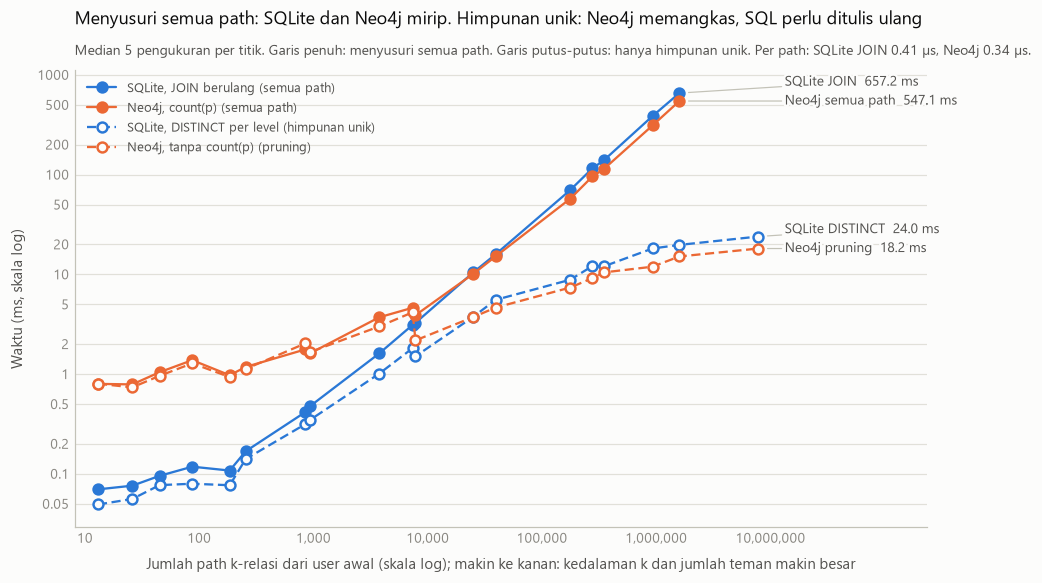

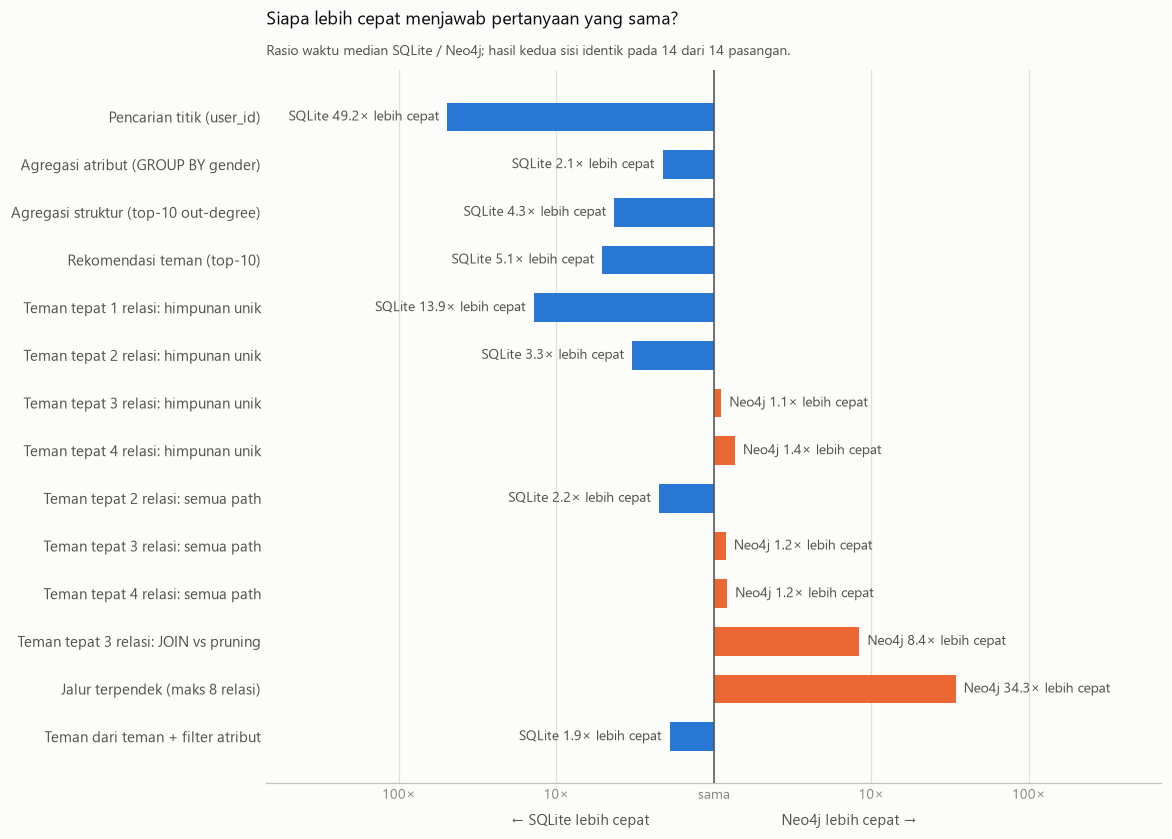

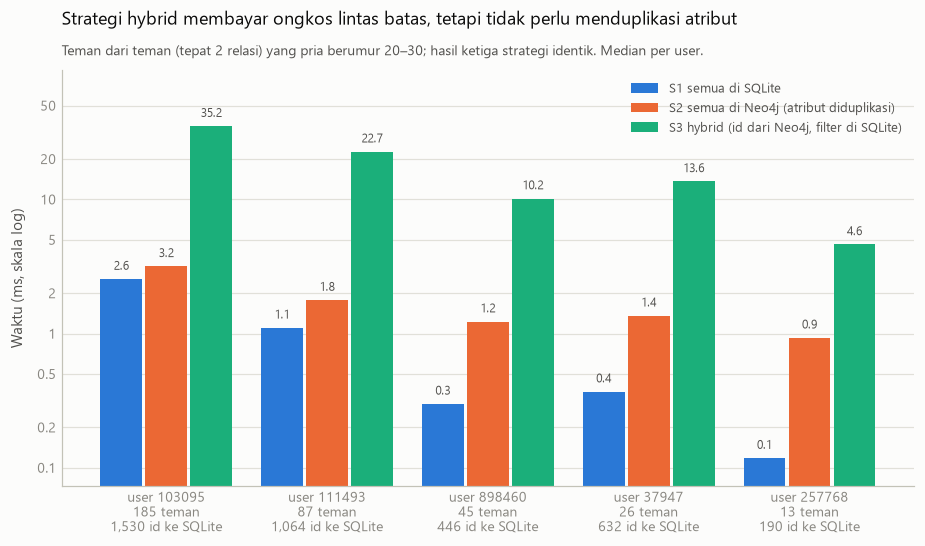

,keluarga,sqlite_ms,neo4j_ms,rasio,pemenang,hasil_sama,token_sql,token_cypher
0,Pencarian titik (user_id),0.014,0.671,0.020,SQLite,True,11,17
1,Agregasi atribut (GROUP BY gender),1.015,2.151,0.472,SQLite,True,17,16
2,Agregasi struktur (top-10 out-degree),4.274,18.328,0.233,SQLite,True,20,17
3,Rekomendasi teman (top-10),13.989,71.486,0.196,SQLite,True,65,27
4,Teman tepat 1 relasi: himpunan unik,0.339,4.716,0.072,SQLite,True,28,17
5,Teman tepat 2 relasi: himpunan unik,3.634,11.993,0.303,SQLite,True,45,17
6,Teman tepat 3 relasi: himpunan unik,31.680,28.401,1.115,Neo4j,True,62,17
7,Teman tepat 4 relasi: himpunan unik,74.004,54.391,1.361,Neo4j,True,79,17
8,Teman tepat 2 relasi: semua path,5.788,12.907,0.448,SQLite,True,33,22
9,Teman tepat 3 relasi: semua path,238.553,200.145,1.192,Neo4j,True,50,22


In [17]:
# Gabungan: satu baris per pasangan pertanyaan yang setara (rasio = waktu SQLite / waktu Neo4j; di atas 1 berarti Neo4j lebih cepat).
with tes.aman("Ringkasan perbandingan"):
    hasil["regresi"] = ek.regresi_waktu_path(khop)
    hasil["ringkasan"] = ek.ringkasan_keluarga(hasil)
    r = hasil["regresi"]
    kecepatan["Biaya per path, SQLite JOIN (mikrodetik)"] = round(r["sqlite_join"]["b_mikrodetik_per_path"], 3)
    kecepatan["Biaya per path, Neo4j count(p) (mikrodetik)"] = round(r["neo4j_enum"]["b_mikrodetik_per_path"], 3)
    viz.simpan(viz.gambar_benchmark(khop, 5, r), "01_benchmark_waktu")
    plt.show()
    ring = hasil["ringkasan"]
    viz.simpan(viz.gambar_keluarga_query(
        [(row.keluarga, row.rasio) for row in ring.itertuples()],
        f"Rasio waktu median SQLite / Neo4j; hasil kedua sisi identik pada {int(ring['hasil_sama'].sum())} dari {len(ring)} pasangan."),
        "10_perbandingan_keluarga_query")
    plt.show()
    if strategi is not None:
        viz.simpan(viz.gambar_strategi_hybrid(strategi), "13_strategi_hybrid")
        plt.show()
(hasil["ringkasan"][["keluarga", "sqlite_ms", "neo4j_ms", "rasio", "pemenang", "hasil_sama", "token_sql", "token_cypher"]].round(3)
 if "ringkasan" in hasil else "(gagal)")

## Langkah 7 - RQ5: biaya menggabungkan

Tiga biaya: **lintas batas** (memindahkan id dan atribut antara kedua mesin), **data ganda** (atribut yang diduplikasi di node, salinan edge di SQLite), dan **ruang disk**.
Catatan: file penyimpanan Neo4j tidak menyusut setelah data dihapus, jadi ukurannya bisa lebih besar daripada isinya kalau uji skala (Langkah 8) pernah dijalankan sebelumnya.

[LULUS] Biaya lintas batas: atribut N user dari SQLite vs dari node Neo4j    1202.8 ms  N=4,505: SQLite 9.0 ms, Neo4j 133.8 ms


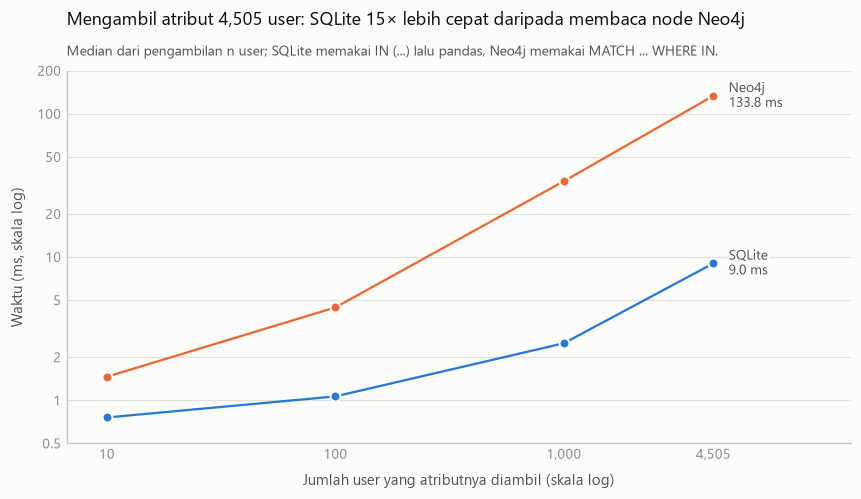

[LULUS] Ukuran penyimpanan terukur                                  85.1 ms  lihat tabel


,isi,ukuran (MB),catatan
0,Berkas SQLite pokec.db (termasuk tabel friendships),2.70,
1,Tabel friendships sendirian (salinan edge di SQLite),0.99,"72,004 baris"
2,Folder penyimpanan database Neo4j,28.63,"nilai atribut yang diduplikasi di node: 13,515"


In [18]:
tes.kelompok = "5. Biaya hybrid"
lintas = tes.jalankan(
    "Biaya lintas batas: atribut N user dari SQLite vs dari node Neo4j", lambda: ek.biaya_lintas_batas(sesi, conn, hq), None,
    lambda h, _: (bool((h["baris_sqlite"] == h["n_user"]).all() and (h["baris_neo4j"] == h["n_user"]).all()),
                  f"N={int(h['n_user'].iloc[-1]):,}: SQLite {h['sqlite_ms'].iloc[-1]:.1f} ms, Neo4j {h['neo4j_ms'].iloc[-1]:.1f} ms"))
hasil["lintas_batas"] = lintas
if lintas is not None:
    viz.simpan(viz.gambar_lintas_batas(lintas), "14_biaya_lintas_batas")
    plt.show()

disk = tes.jalankan("Ukuran penyimpanan terukur", lambda: ek.ukuran_penyimpanan(conn), None, lambda h, _: (True, "lihat tabel"))
hasil["penyimpanan"] = disk
if disk:
    mb = lambda v: None if v is None else round(v / 1e6, 2)
    display(pd.DataFrame([
        ("Berkas SQLite pokec.db (termasuk tabel friendships)", mb(disk["sqlite_berkas_byte"])),
        ("Tabel friendships sendirian (salinan edge di SQLite)", mb(disk["sqlite_friendships_byte"])),
        ("Folder penyimpanan database Neo4j", mb(disk["neo4j_store_byte"])),
    ], columns=["isi", "ukuran (MB)"]).assign(catatan=["", f"{disk['edge_duplikat_di_sqlite']:,} baris",
                                                        f"nilai atribut yang diduplikasi di node: {disk['nilai_atribut_duplikat']:,}"]))

## Langkah 8 - Apakah kesimpulannya berubah pada graf yang lebih besar?

Sampel Pokec kecil (4.505 user). Untuk melihat tren skala, dimuat **sementara** dua graf sintetis berpola jaringan sosial (preferential attachment, Barabasi dan Albert, 1999;
sekitar 71% relasi timbal balik seperti Pokec) ke Neo4j (label `Syn`, dihapus lagi) dan ke SQLite (basis data memori), lalu "tepat 3 relasi" diukur dengan empat cara yang sama.
Data asli tidak tersentuh; tes terakhir memastikannya.

[LULUS] Graf sintetis 10 ribu dan 40 ribu user: empat cara memberi hasil identik   34400.2 ms  2 ukuran graf, sampai 544,025 edge; muat ke Neo4j 8.0 dtk vs SQLite 0.70 dtk
[LULUS] Graf asli utuh dan graf sintetis sudah dihapus              94.7 ms  User=4,505, Hobby=60, FRIEND=72,004, HAS_HOBBY=19,512; sisa node sintetis 0


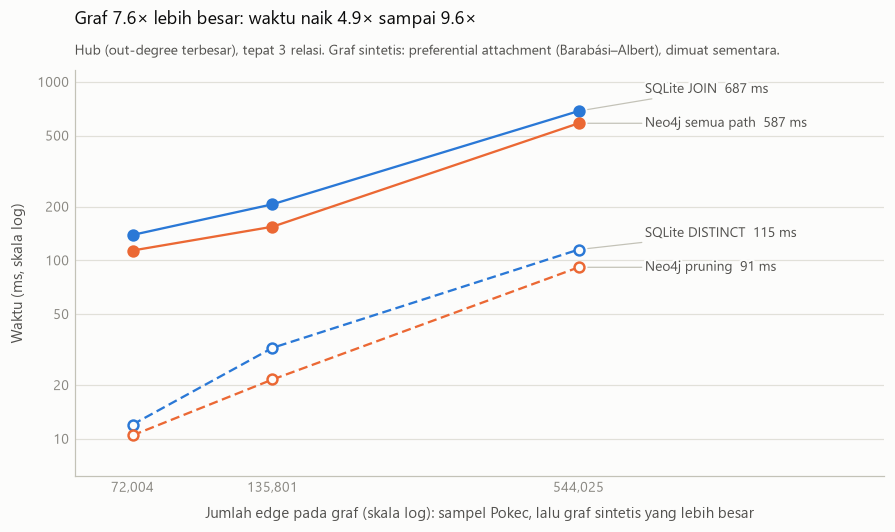

Biaya per path (data asli + sintetis): {'sqlite_join': '0.432 us/path, R2=0.996', 'neo4j_enum': '0.360 us/path, R2=0.993'}


,n_user,n_edge,user_id,out_degree,jumlah_path,sqlite_join_ms,neo4j_enum_ms,sqlite_distinct_ms,neo4j_unik_ms
0,10000,135801,10,388,474686,206.19,154.35,32.34,21.50
1,10000,135801,952,22,20093,10.94,9.76,5.21,6.15
2,10000,135801,8630,10,11358,6.79,6.41,3.85,4.82
3,40000,544025,10,785,1483449,686.79,586.52,114.95,91.46
4,40000,544025,3392,22,20646,14.64,12.15,8.02,10.38
5,40000,544025,10079,9,22224,15.28,12.09,8.52,10.22


In [19]:
tes.kelompok = "6. Skala (graf sintetis)"
skala = tes.jalankan(
    "Graf sintetis 10 ribu dan 40 ribu user: empat cara memberi hasil identik", lambda: ek.uji_skala(sesi), None,
    lambda h, _: (bool(h["hasil_sama"].all()),
                  f"{h['n_user'].nunique()} ukuran graf, sampai {int(h['n_edge'].max()):,} edge; muat ke Neo4j "
                  f"{h['muat_neo4j_ms'].max() / 1000:.1f} dtk vs SQLite {h['muat_sqlite_ms'].max() / 1000:.2f} dtk"))
hasil["skala"] = skala


def sisa_sintetis():
    return sesi.jalankan("MATCH (s:Syn) RETURN count(s) AS n")[0]["n"]


tes.jalankan("Graf asli utuh dan graf sintetis sudah dihapus", lambda: (hitung_graf(), sisa_sintetis()), None,
             lambda h, _: (h[0] == ref.jumlah and h[1] == 0, f"{', '.join(f'{a}={b:,}' for a, b in h[0].items())}; sisa node sintetis {h[1]}"))
if skala is not None:
    with tes.aman("Gambar skala"):
        hub = skala.sort_values("jumlah_path", ascending=False).groupby("n_edge").head(1)
        nyata = khop[(khop["k"] == 3) & (khop["user_id"] == users[0][0])].assign(n_edge=ref.jumlah["FRIEND"])
        gabung = pd.concat([nyata, hub], ignore_index=True)
        viz.simpan(viz.gambar_skala(gabung), "12_skala_graf")
        plt.show()
        hasil["regresi_gabungan"] = ek.regresi_waktu_path(pd.concat([khop, skala], ignore_index=True))
        print("Biaya per path (data asli + sintetis):",
              {n: f"{v['b_mikrodetik_per_path']:.3f} us/path, R2={v['r2']:.3f}" for n, v in hasil["regresi_gabungan"].items()})
skala[["n_user", "n_edge", "user_id", "out_degree", "jumlah_path", "sqlite_join_ms", "neo4j_enum_ms", "sqlite_distinct_ms", "neo4j_unik_ms"]].round(2) if skala is not None else "(gagal)"

## Langkah 9 - Gambar statis (graf dan relasional)

Sembilan gambar dibuat dari data yang sama dan disimpan ke `docs/visualisasi/`. Tesnya hanya **berhasil dibuat atau tidak**; isinya perlu dilihat sendiri.

- **Graph (Neo4j):** model node/relasi, jaringan satu user, satu klaster hobi, distribusi derajat.
- **Relasional (SQLite):** skema tabel (PK/FK), hobi terpopuler, sebaran umur, pendidikan.

[LULUS] Gambar: model graf Neo4j + skema SQLite                    345.1 ms  docs/visualisasi/02_model_graf_neo4j.png, docs/visualisasi/03_skema_sqlite.png


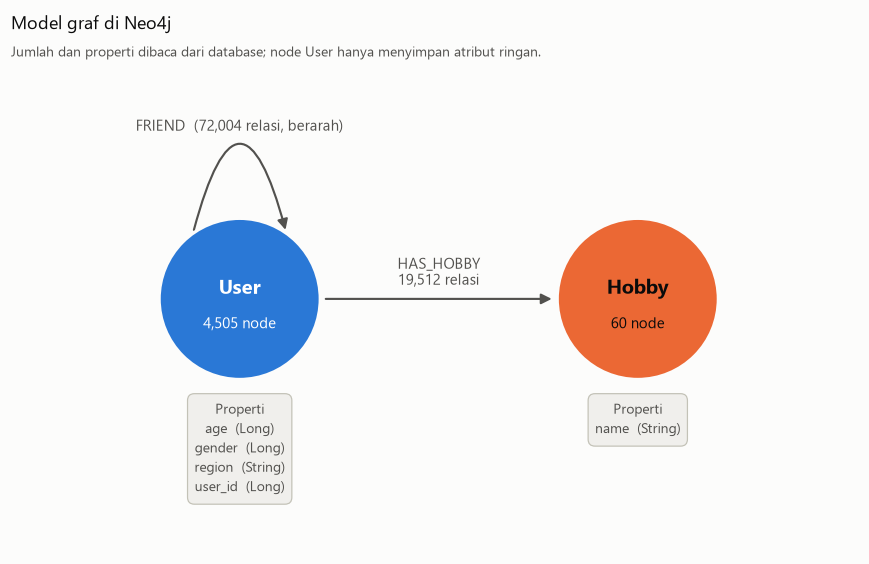

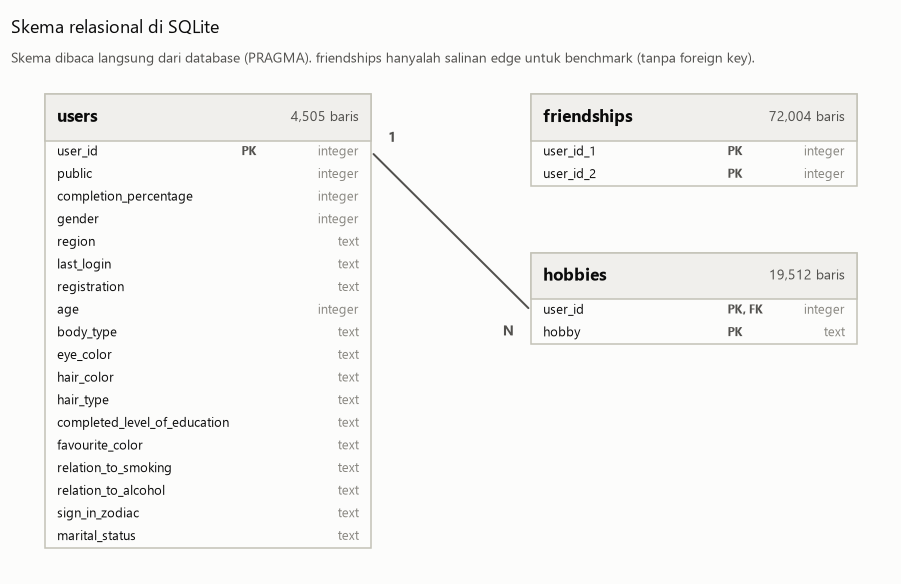

In [20]:
tes.kelompok = "8. Gambar statis"


def gambar_model():
    with hq._koneksi() as (d, c):
        properti = pd.DataFrame(hq._cypher(d, "model_graf_properti.cypher"))
        jumlah = pd.DataFrame(hq._cypher(d, "model_graf_jumlah.cypher"))
        skema = viz.baca_skema_sqlite(c)
    return (viz.simpan(viz.gambar_model_graf(properti, jumlah), "02_model_graf_neo4j"),
            viz.simpan(viz.gambar_skema_sqlite(skema), "03_skema_sqlite"))


tes.jalankan("Gambar: model graf Neo4j + skema SQLite", gambar_model, None, lambda h, _: (True, ", ".join(h)))
plt.show()

[LULUS] Gambar: jaringan satu user (graf)                          197.7 ms  docs/visualisasi/04_jaringan_user_demo.png


[LULUS] Gambar: klaster hobi + distribusi derajat (graf)           459.5 ms  docs/visualisasi/05_klaster_hobi.png, docs/visualisasi/06_distribusi_derajat.png


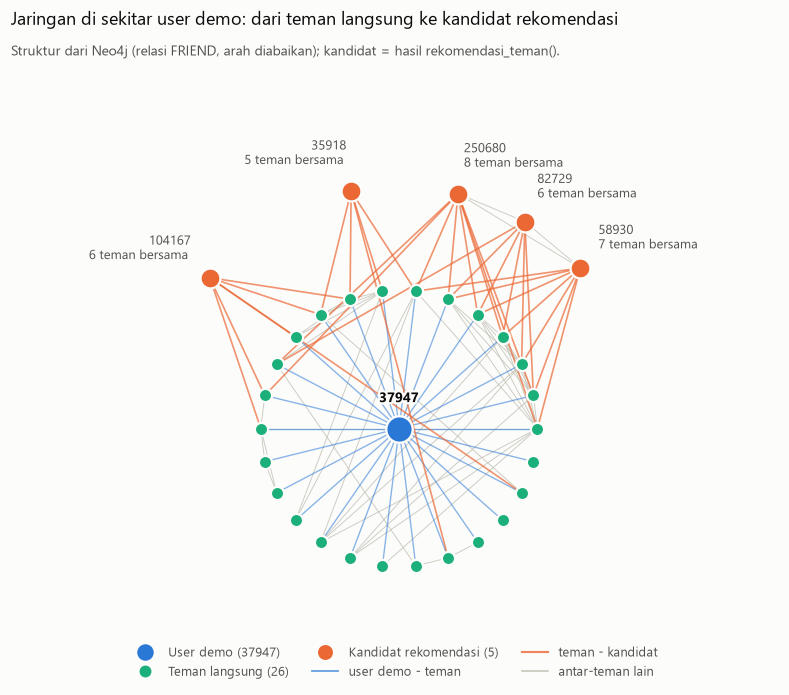

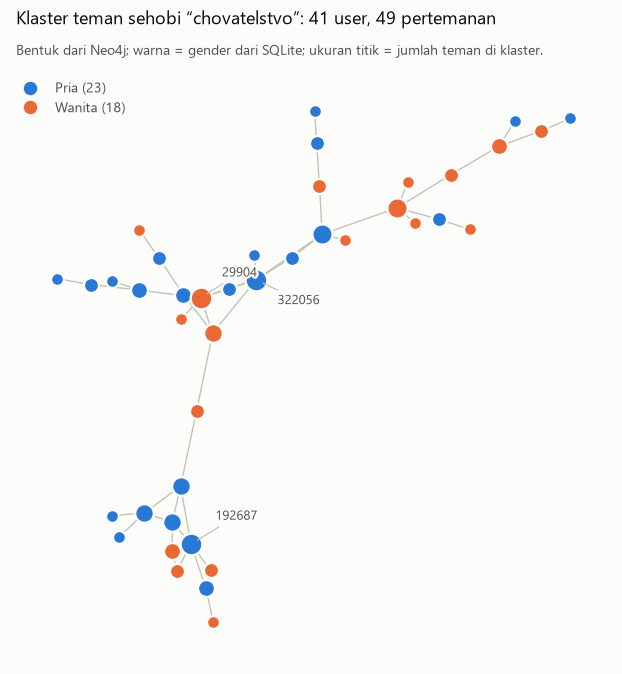

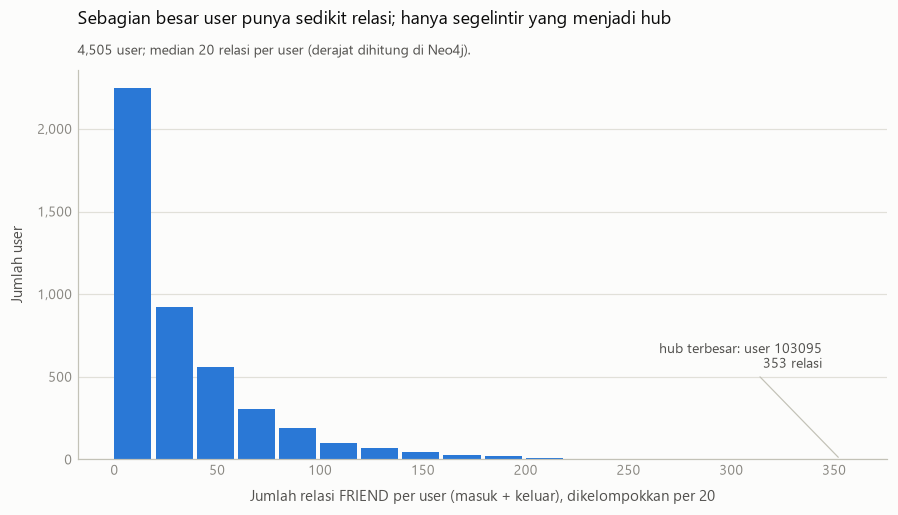

In [21]:
def gambar_jaringan():
    with hq._koneksi() as (d, c):
        teman = [r["user_id"] for r in hq._cypher(d, "teman_langsung.cypher", user_id=USER_DEMO)]
        kandidat = list(zip(rekomendasi["user_id"].head(5), rekomendasi["teman_bersama"].head(5)))
        ids = [int(USER_DEMO), *map(int, teman), *(int(u) for u, _ in kandidat)]
        relasi = [(r["sumber"], r["tujuan"]) for r in hq._cypher(d, "relasi_antar_user.cypher", ids=ids)]
    return viz.simpan(viz.gambar_jaringan_ego(USER_DEMO, teman, kandidat, relasi), "04_jaringan_user_demo")


def gambar_klaster_dan_derajat():
    klaster1 = niche[niche["klaster"] == 1]
    with hq._koneksi() as (d, c):
        relasi_k = [(r["sumber"], r["tujuan"]) for r in
                    hq._cypher(d, "relasi_antar_user.cypher", ids=[int(u) for u in klaster1["user_id"]])]
        semua_derajat = hq._derajat_semua(d)
    return (viz.simpan(viz.gambar_klaster(klaster1, relasi_k, HOBI_NICHE), "05_klaster_hobi"),
            viz.simpan(viz.gambar_distribusi_derajat(semua_derajat), "06_distribusi_derajat"))


tes.jalankan("Gambar: jaringan satu user (graf)", gambar_jaringan, None, lambda h, _: (True, h))
tes.jalankan("Gambar: klaster hobi + distribusi derajat (graf)", gambar_klaster_dan_derajat, None, lambda h, _: (True, ", ".join(h)))
plt.show()

[LULUS] Gambar: hobi, umur, pendidikan dari tabel SQLite           310.9 ms  docs/visualisasi/07_hobi_terpopuler.png, docs/visualisasi/08_sebaran_umur.png, docs/visualisasi/09_pendidikan.png


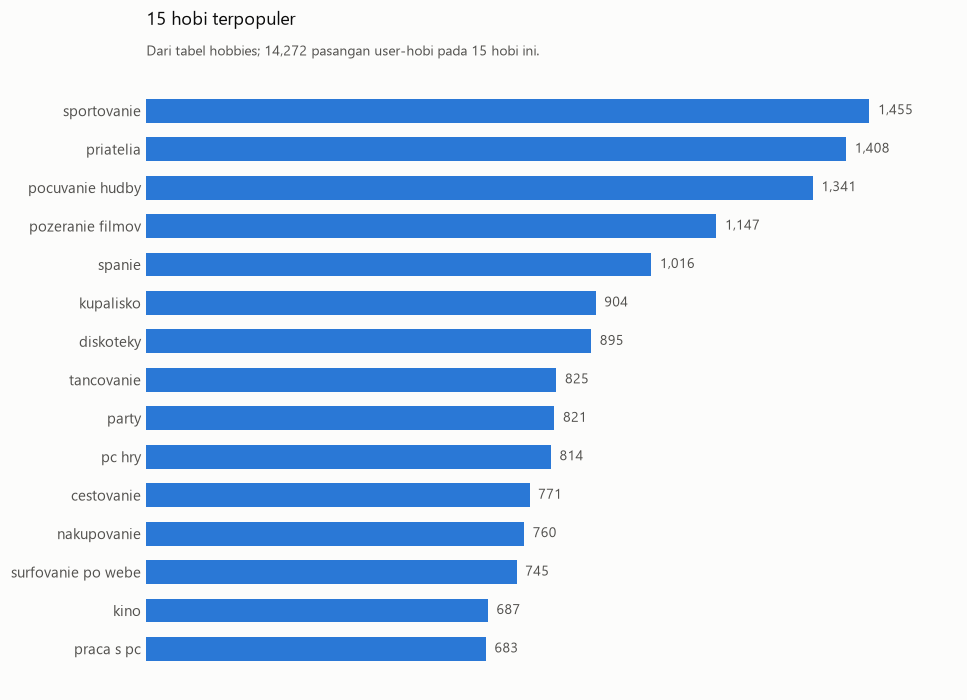

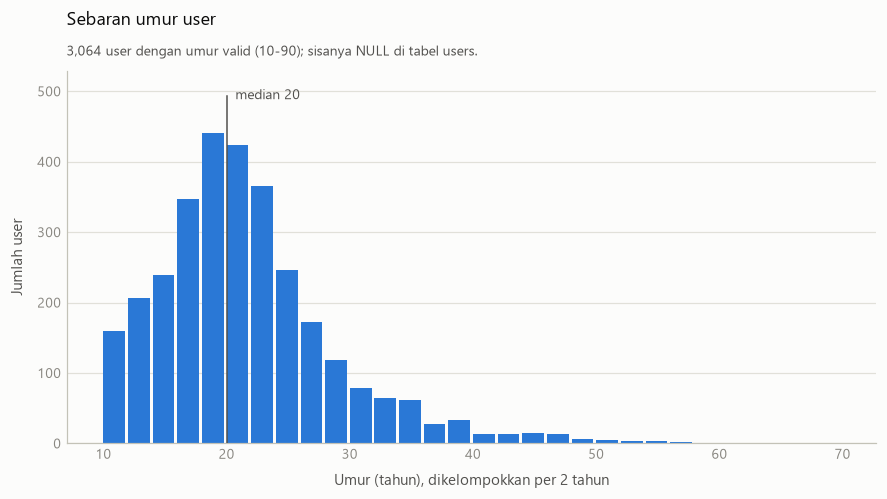

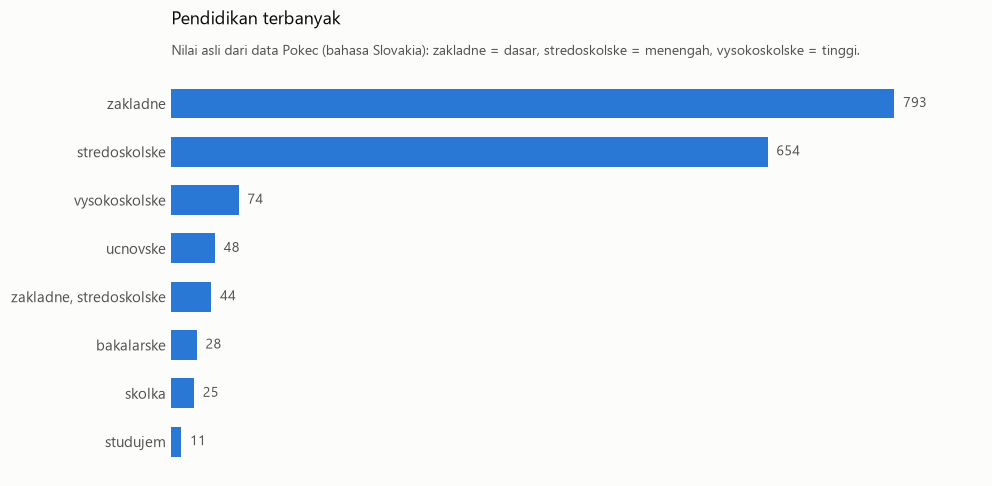

In [22]:
def gambar_tabel_sqlite():
    hobi_top = pd.read_sql_query(
        "SELECT hobby AS hobi, COUNT(*) AS jumlah_user FROM hobbies GROUP BY hobby ORDER BY jumlah_user DESC LIMIT 15", conn)
    umur = pd.read_sql_query("SELECT age FROM users WHERE age IS NOT NULL", conn)["age"]
    pendidikan = pd.read_sql_query(
        "SELECT completed_level_of_education AS pendidikan, COUNT(*) AS jumlah_user FROM users "
        "WHERE completed_level_of_education IS NOT NULL GROUP BY 1 ORDER BY 2 DESC LIMIT 8", conn)
    return (
        viz.simpan(viz.gambar_batang_horizontal(
            hobi_top, "hobi", "jumlah_user", "15 hobi terpopuler",
            f"Dari tabel hobbies; {hobi_top['jumlah_user'].sum():,} pasangan user-hobi pada 15 hobi ini."), "07_hobi_terpopuler"),
        viz.simpan(viz.gambar_histogram(
            umur, "Sebaran umur user", f"{len(umur):,} user dengan umur valid (10-90); sisanya NULL di tabel users.",
            "Umur (tahun), dikelompokkan per 2 tahun"), "08_sebaran_umur"),
        viz.simpan(viz.gambar_batang_horizontal(
            pendidikan, "pendidikan", "jumlah_user", "Pendidikan terbanyak",
            "Nilai asli dari data Pokec (bahasa Slovakia): zakladne = dasar, stredoskolske = menengah, vysokoskolske = tinggi."),
            "09_pendidikan"),
    )


tes.jalankan("Gambar: hobi, umur, pendidikan dari tabel SQLite", gambar_tabel_sqlite, None, lambda h, _: (True, ", ".join(h)))
plt.show()

## Langkah 10 - Tutup koneksi dan matikan Neo4j

Koneksi ditutup lebih dulu. Neo4j dimatikan **hanya kalau notebook ini yang menyalakannya**, secara paksa (tidak ada cara berhenti yang lebih halus dari luar);
aman, karena Neo4j memulihkan diri saat dinyalakan lagi. Kalau kernel dimatikan, Neo4j yang dinyalakan dari notebook ini juga ikut berhenti.

In [23]:
tes.kelompok = "7. Penutup"
for tutup in (lambda: sesi.tutup(), lambda: driver.close(), lambda: conn.close()):
    try:
        tutup()
    except Exception:
        pass
if sudah_menyala:
    tes.catat("Neo4j dibiarkan menyala", True, "sudah menyala sebelum notebook dimulai")
else:
    _, ms = uji_hybrid.ukur(neo4j_lokal.matikan)
    tes.catat("Neo4j dimatikan oleh notebook", not neo4j_lokal.bolt_terbuka(), "port Bolt tertutup", ms)

[OK] Neo4j dimatikan.


[LULUS] Neo4j dimatikan oleh notebook                             3038.6 ms  port Bolt tertutup


## Langkah 11 - Hasil: lulus/gagal, hipotesis, dan jawaban untuk pertanyaan dosen

Baris pertama sel pertama di bawah adalah vonis tes. Hipotesis H1-H5 (ditetapkan di laporan **sebelum** hasil dilihat) dinilai otomatis dari angka di atas: **DIDUKUNG**,
**SEBAGIAN**, atau **TIDAK DIDUKUNG**. Semua angka juga disimpan ke `docs/hasil/` supaya laporan bisa menelusurinya.

In [24]:
hasil_tes = tes.ringkasan()

print()
print("Seberapa cepat (ringkas):")
for nama, nilai in kecepatan.items():
    print(f"  {nama}: {nilai}")
print(f"  Seluruh notebook: {time.perf_counter() - MULAI_NOTEBOOK:.0f} detik")
hasil_tes[["kelompok", "tes", "hasil", "waktu_ms", "keterangan"]]

HASIL: 40 LULUS, 0 GAGAL dari 40 tes.
Semua tes lulus.

Seberapa cepat (ringkas):
  Neo4j menyala dari mati (detik): 12.6
  Neo4j, query yang sama: panggilan ke-1 vs stabil (ms): 512 vs 17
  Sinkron ulang seluruh graf ke Neo4j, script 03 (detik): 3.4
  Biaya per path, SQLite JOIN (mikrodetik): 0.413
  Biaya per path, Neo4j count(p) (mikrodetik): 0.34
  Seluruh notebook: 97 detik


,kelompok,tes,hasil,waktu_ms,keterangan
0,0. Persiapan,"Prasyarat (password, localhost, CSV, SQLite) siap",LULUS,NaN,lihat daftar di atas
1,0. Persiapan,Neo4j menyala dan menerima koneksi,LULUS,12634.5319,dinyalakan oleh notebook ini
2,0. Persiapan,Koneksi Neo4j + SQLite terbuka; tabel friendships dibuat,LULUS,137.4982,"72,004 baris edge di SQLite"
3,0. Persiapan,Profil struktur sampel dihitung dari CSV,LULUS,1355.3491,"resiprositas 71.1%, klasterisasi 0.188"
4,1. Konsistensi lintas basis data,Graf Neo4j sama dengan CSV (node dan relasi),LULUS,309.1008,"User=4,505, Hobby=60, FRIEND=72,004, HAS_HOBBY=19,512"
5,1. Konsistensi lintas basis data,"SQLite: jumlah baris, integritas, foreign key",LULUS,27.1953,"users=4,505, hobbies=19,512, integrity=ok, pelanggaran FK=0"
6,1. Konsistensi lintas basis data,"Himpunan user, edge, dan user-hobi identik di Neo4j dan SQLite",LULUS,2579.3032,"4,505 user, 72,004 edge, 19,512 pasangan user-hobi; selisih di kedua arah: 0"
7,1. Konsistensi lintas basis data,"Atribut duplikat (gender, age, region) sinkron untuk semua user",LULUS,163.9595,"13,515 nilai dibandingkan, 0 berbeda"
8,1. Konsistensi lintas basis data,SQLite: pencarian user_id memakai index (PRIMARY KEY),LULUS,0.6771,SEARCH users USING INTEGER PRIMARY KEY (rowid=?)
9,2. Sinkronisasi dan drift,Sinkron ulang (script 03) idempoten: tidak ada node atau relasi ganda,LULUS,3419.7059,"kode keluar 0; User=4,505, Hobby=60, FRIEND=72,004, HAS_HOBBY=19,512"


In [25]:
vonis = None
with tes.aman("Vonis hipotesis"):
    vonis = ek.vonis_hipotesis(hasil, tes.tabel())
    hasil["vonis"] = vonis
vonis if vonis is not None else "(gagal)"

,hipotesis,pernyataan,hasil,bukti
0,H1,Dua basis data konsisten dan hasil gabungan sama persis dengan jawaban kunci,DIDUKUNG,17/17 tes lulus
1,H2,Pertanyaan yang sama dijawab identik; beda di kinerja dan kemudahan menulis query,DIDUKUNG,14/14 pasangan query identik; median token SQL 46 vs Cypher 17
2,H3,"Neo4j lebih cepat untuk penelusuran multi-hop, dan selisihnya membesar dengan kedalaman dan jumlah path",SEBAGIAN,"rasio SQLite/Neo4j (di atas 1 = Neo4j lebih cepat): himpunan unik k=2 0.30×, k=3 1.12×, k=4 1.36×; semua path k=2 0.45×, k=3 1.19×, k=4 1.21×; JOIN vs pruning k=3 8.40×; jalur terpendek 34.34×; hub graf sintetis (SQL/Neo4j): 135,801 edge: semua path 1.34×, unik 1.50×, 544,025 edge: semua path 1.17×, unik 1.26×"
3,H4,SQLite setara atau lebih cepat untuk pencarian titik dan agregasi atribut,DIDUKUNG,"rasio SQLite/Neo4j: pencarian titik 0.020, agregasi atribut 0.472, agregasi struktur 0.233 (di bawah 1 = SQLite lebih cepat)"
4,H5,Duplikasi atribut menimbulkan risiko ketidaksinkronan yang dapat dideteksi otomatis,DIDUKUNG,"3 ketidaksinkronan disuntik, 3 terdeteksi (tepat: True), 0 tersisa setelah perbaikan"


In [26]:
with tes.aman("Jawaban untuk dosen"):
    hasil["jawaban"] = ek.jawaban_dosen(hasil, tes.tabel())
    for baris in hasil["jawaban"]:
        print(baris)
        print()

JAWABAN: YA. Graph database (Neo4j) dapat dikombinasikan dengan relational database biasa (SQLite), dan hasil gabungannya benar.

Bukti kebenaran: 27/27 tes inti lulus (konsistensi, sinkronisasi, fungsi hybrid, kesetaraan hasil); 14/14 pasangan query memberi hasil identik di SQLite dan Neo4j.

Pembagian tugas, Neo4j lebih cepat pada: Teman tepat 3 relasi: himpunan unik (1.1×); Teman tepat 4 relasi: himpunan unik (1.4×); Teman tepat 3 relasi: semua path (1.2×); Teman tepat 4 relasi: semua path (1.2×); Teman tepat 3 relasi: JOIN vs pruning (8.4×); Jalur terpendek (maks 8 relasi) (34.3×).

Pembagian tugas, SQLite lebih cepat pada: Pencarian titik (user_id) (49.2×); Agregasi atribut (GROUP BY gender) (2.1×); Agregasi struktur (top-10 out-degree) (4.3×); Rekomendasi teman (top-10) (5.1×); Teman tepat 1 relasi: himpunan unik (13.9×); Teman tepat 2 relasi: himpunan unik (3.3×); Teman tepat 2 relasi: semua path (2.2×); Teman dari teman + filter atribut (1.9×).

Biaya kombinasi: strategi hybrid

In [27]:
# Simpan semua angka ke docs/hasil/ (CSV/JSON) untuk laporan.
with tes.aman("Simpan hasil ke docs/hasil/"):
    tersimpan = [ek.simpan_hasil("tes", tes.tabel())]
    for nama in ("ringkasan", "khop", "jalur", "strategi", "skala", "lintas_batas", "rekomendasi", "vonis"):
        if isinstance(hasil.get(nama), pd.DataFrame):
            tersimpan.append(ek.simpan_hasil(nama, hasil[nama]))
    if hasil.get("dasar"):
        tersimpan.append(ek.simpan_hasil("dasar", pd.DataFrame(hasil["dasar"])))
    tersimpan.append(ek.simpan_hasil("lainnya", {k: hasil[k] for k in ("lingkungan", "overhead", "regresi", "regresi_gabungan", "drift",
                                                                       "penyimpanan", "kurva_pemanasan", "jawaban", "profil_graf") if k in hasil}
                                     | {"kecepatan": kecepatan}))
    print("Tersimpan:", ", ".join(tersimpan))

Tersimpan: docs/hasil/tes.csv, docs/hasil/ringkasan.csv, docs/hasil/khop.csv, docs/hasil/jalur.csv, docs/hasil/strategi.csv, docs/hasil/skala.csv, docs/hasil/lintas_batas.csv, docs/hasil/rekomendasi.csv, docs/hasil/vonis.csv, docs/hasil/dasar.csv, docs/hasil/lainnya.json


## Pustaka yang dipakai notebook ini (semua open access)

Daftar lengkap dengan status akses ada di laporan. Tautan di bawah sudah dibuka dan diverifikasi saat laporan disusun.

- Fowler, M. (2011). *Polyglot persistence.* https://martinfowler.com/bliki/PolyglotPersistence.html (artikel web)
- Lu, J., dan Holubova, I. (2019). Multi-model databases: A new journey to handle the variety of data. *ACM Computing Surveys.* http://hdl.handle.net/10138/303698
- Backstrom, L., dan Leskovec, J. (2011). Supervised random walks. *WSDM '11.* https://arxiv.org/abs/1011.4071
- Cheng, Y. dkk. (2019). Which category is better: Benchmarking relational and graph database management systems. *Data Science and Engineering.* https://doi.org/10.1007/s41019-019-00110-3
- Holsch, J., Schmidt, T., dan Grossniklaus, M. (2017). On the performance of analytical and pattern matching graph queries in Neo4j and a relational database. *CEUR-WS Vol-1810.* https://ceur-ws.org/Vol-1810/GraphQ_paper_01.pdf
- Francis, N. dkk. (2018). Cypher: An evolving query language for property graphs. *SIGMOD '18.* https://hal.science/hal-01803524/document
- Rodriguez, M. A., dan Neubauer, P. (2010). *The graph traversal pattern.* https://arxiv.org/abs/1004.1001
- Hassan, M. S. dkk. (2018). Extending in-memory relational database engines with native graph support. *EDBT 2018.* https://openproceedings.org/2018/conf/edbt/paper-17.pdf
- Erling, O. dkk. (2015). The LDBC Social Network Benchmark: Interactive workload. *SIGMOD '15.* https://ir.cwi.nl/pub/23380/23380A.pdf
- Georges, A., Buytaert, D., dan Eeckhout, L. (2007). Statistically rigorous Java performance evaluation. *OOPSLA '07.* https://biblio.ugent.be/publication/417084/file/448219.pdf
- Barabasi, A.-L., dan Albert, R. (1999). Emergence of scaling in random networks. *Science.* https://arxiv.org/abs/cond-mat/9910332
- Yuan, G. dkk. (2023). A survey on mapping semi-structured data and graph data to relational data. *ACM Computing Surveys.* http://hdl.handle.net/10138/354263